# From a job ad to checked JSON

*Practical after the API notebook.*

One of the most common jobs for an LLM in a company is a boring one: turn messy text into a row of a database.
Invoices, contracts, emails, job ads. The industry calls it **document AI** or **information extraction**. Today we
do it on real data: the **148 job postings from staff.am** that the course collected on 28 October 2026, read by
**four cheap models** (GPT-4o mini, DeepSeek V4.1 Flash, Gemma 4 26B, Llama 3.1 8B) and, for comparison, **one
flagship**: GPT-6.1 Sol.

Three ideas from LLM-2 (Decoding) become tools here:

- **constrained decoding**: a strict JSON schema, so every reply is valid JSON;
- **log-probabilities**: a confidence score for a field, so unsure answers can go to a person;
- **temperature 0**: which, as LLM-2 warned, is not quite deterministic.

The plan: the data (1), the schema (2), a confidence number (3), providers (4), one call (5), all 148 postings
(6), then the measurements: a baseline (7), asking for JSON vs a strict schema (8), the models side by side (9),
a review queue (10), Armenian vs English (11), temperature 0 twice (12), and the question that matters: would you
ship it? (13)

> **Running it.** The calls were made once and saved (`results/job_extraction_calls.json`, 2026-11-11): 1,776
> for the cheap models ($0.39) and 148 for GPT-6.1 Sol ($0.36). Re-executing reads the saved run and makes only
> 5 live calls: about a minute, about half a cent. `RERUN = True` repeats everything.

## 0. Setup

The usual tools, plus `pydantic` for checking the JSON and `concurrent.futures` for running many calls at once.

In [1]:
# ~5 s
import json
import math
import os
import re
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv
from openai import OpenAI
from pydantic import BaseModel, ConfigDict, Field, ValidationError

The OpenRouter client from the API notebook. `RERUN` decides whether we pay for the calls again.

In [2]:
load_dotenv("../../.env")                                   # OPENROUTER_API_KEY=..., never printed
API = "https://openrouter.ai/api/v1"
client = OpenAI(base_url=API, api_key=os.environ["OPENROUTER_API_KEY"], max_retries=3, timeout=120)

DATA = Path("../../_knowledge/ml_job_market/data/staffam_2026-10-28.json")
CALLS = Path("results/job_extraction_calls.json")           # every call of the saved run
ENDPOINTS = Path("results/job_extraction_endpoints.json")   # which provider served each model
RERUN = False        # True: re-test the providers and repeat all 1,924 calls (~$0.75, ~5 min)
LIMIT = None    # None = all 148 postings
pd.set_option("display.max_colwidth", 70)

Four cheap models: one closed (GPT-4o mini, 2024), three with open weights (DeepSeek V4.1 Flash, September 2026;
Gemma 4 26B, April 2026; Llama 3.1 8B, 2024). And one flagship for comparison: **GPT-6.1 Sol** (OpenAI, September
2026), about 13-17x GPT-4o mini's price per token. It thinks briefly before answering (low effort), runs only the
strict-schema pass, and offers no logprobs or temperature.

In [3]:
MODELS = ["openai/gpt-4o-mini", "deepseek/deepseek-v4.1-flash", "google/gemma-4-26b-a4b-it",
          "meta-llama/llama-3.1-8b-instruct"]
SHORT = {"openai/gpt-4o-mini": "GPT-4o mini", "deepseek/deepseek-v4.1-flash": "DeepSeek V4.1 Flash",
         "google/gemma-4-26b-a4b-it": "Gemma 4 26B", "meta-llama/llama-3.1-8b-instruct": "Llama 3.1 8B"}
COLOR = {"openai/gpt-4o-mini": "#0033A0", "deepseek/deepseek-v4.1-flash": "#D90012",
         "google/gemma-4-26b-a4b-it": "#F2A800", "meta-llama/llama-3.1-8b-instruct": "#777777"}
MODELS.append("openai/gpt-6.1-sol")
STRONG = "openai/gpt-6.1-sol"     # the flagship: strict schema only, low-effort thinking, no logprobs or temperature
SHORT[STRONG], COLOR[STRONG] = "GPT-6.1 Sol", "#2E7D32"

## 1. The data

Every posting has free text (title, description, responsibilities, qualifications) and some **fields the employer
filled in on the site**: seniority level, salary, a "remote" tick box. The model gets the text only.

**Where the postings come from.** The course's job-market study scraped them on 28 October 2026 with
`_knowledge/ml_job_market/py_src/collect_staffam.py` (5.4 minutes, 177 requests, one every 1.5 s). staff.am's own
keyword search is fuzzy, so the script does not search: it walks **every listing page** (`staff.am/en/jobs?page=N`,
50 jobs per page), keeps a job if its title matches one of the study's ML / AI / data role patterns or it sits in an
IT or data category, and then opens each kept job's own page.

No HTML parsing is needed. staff.am is built with Next.js, which puts each page's data as JSON into one
`<script id="__NEXT_DATA__">` tag, every text in English, Armenian and Russian. The core of the scraper:

```python
r = requests.get("https://staff.am/en/jobs?page=1")
m = re.search(r'<script id="__NEXT_DATA__"[^>]*>(.*?)</script>', r.text, re.S)
page = json.loads(m.group(1))["props"]["pageProps"]   # page["jobs"]: 50 listings, page["totalCount"]: all open jobs
```

Before saving, e-mail addresses and phone numbers became `[email]` and `[phone]`: the repo is public. More, and the
command to re-run it: `_knowledge/ml_job_market/README.md`.

In [4]:
raw = json.load(open(DATA, encoding="utf-8"))
jobs = raw["jobs"]
print(f"collected {raw['collected']}: {raw['total_listings']:,} open jobs on staff.am, {raw['kept_for_text']} kept "
      f"(IT / data), {len(raw['failures'])} job pages failed")
TEXT_FIELDS = ["title", "description", "responsibilities", "required_qualifications", "additional_information"]


def text_of(job):
    # the only thing the model sees
    return "\n\n".join(str(job[k]).strip() for k in TEXT_FIELDS if job.get(k))

collected 2026-10-28: 1,313 open jobs on staff.am, 148 kept (IT / data), 0 job pages failed


**Which language?** The scraper's `lang` says which of the site's three language fields the employer filled in, not
what the text is written in: some employers type Armenian into the English field. So we count letters instead.

In [5]:
SCRIPTS = {"en": re.compile(r"[A-Za-z]"), "am": re.compile(r"[\u0531-\u058F]"), "ru": re.compile(r"[\u0400-\u04FF]")}
for job in jobs:
    job["site_lang"] = job["lang"]                           # the field the employer filled in
    job["lang"] = max(SCRIPTS, key=lambda s: len(SCRIPTS[s].findall(text_of(job))))   # most letters win
if LIMIT:                                                   # dev runs: half English, half Armenian
    jobs = [j for j in jobs if j["lang"] == "en"][:LIMIT // 2] + [j for j in jobs if j["lang"] == "am"][:LIMIT - LIMIT // 2]
print(len(jobs), "postings by the language of their text:", dict(Counter(job["lang"] for job in jobs)))
print("the site's language field says otherwise for", sum(job["lang"] != job["site_lang"] for job in jobs))

148 postings by the language of their text: {'en': 116, 'am': 31, 'ru': 1}
the site's language field says otherwise for 11


One row per posting, without the long text fields. `level`, `remote` and the salary columns are what the employer
filled in on the site's form; `characters` is the length of the text the model will read.

In [6]:
postings = pd.DataFrame(jobs).assign(characters=[len(text_of(job)) for job in jobs])
postings[["id", "lang", "title", "company", "category", "level", "remote", "salary_from", "salary_to",
          "salary_currency", "characters"]].head(10)

,id,lang,title,company,category,level,remote,salary_from,salary_to,salary_currency,characters
0,166766,en,Senior Full-Stack Developer (Angular / .NET Core),Resourceful Telent Group,software-development,Senior,True,NaN,NaN,AMD,2074
1,166762,en,Operations Manager/ Farsi speaking,Nexttoptech,other-it,Senior,False,1800.0,NaN,USD,6816
2,166736,am,Quality Assurance Specialist,ASD SYSTEMS LLC,quality-assurance,Junior,False,NaN,NaN,AMD,1565
3,166734,en,Senior DevOps Engineer,Buymie,software-development,Senior,False,NaN,NaN,AMD,2689
4,166730,am,Վերահսկող օպերատոր,Grand Candy,other-it,Senior,False,NaN,NaN,AMD,1537
5,166725,am,Մեխատրոնիկայի ինժեներ /մեխանիկա + էլեկտրոնիկա/ | CreedRoomz,SoftConstruct,software-development,Not defined,False,NaN,NaN,AMD,2912
6,166724,en,Junior Software Engineer | CreedRoomz,SoftConstruct,other-it,Junior,False,NaN,NaN,AMD,2287
7,166721,am,Մեխատրոնիկայի ինժեներ /մեխանիկա + էլեկտրոնիկա/,CreedRoomz,software-development,Not defined,False,NaN,NaN,AMD,2899
8,166718,en,Junior Programming Specialist,CreedRoomz,other-it,Junior,False,NaN,NaN,AMD,2274
9,166710,en,Senior GenAI Workshop Leader,TUMO Center for Creative Technologies,education-training,Senior,False,NaN,NaN,AMD,3010


What is in there, counted:

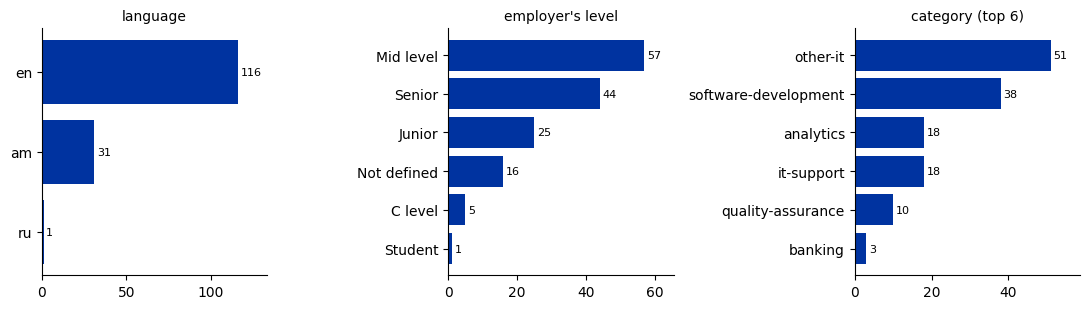

67 companies, most postings: SoftConstruct 25, Digitain 12, "Telecom Armenia" OJSC 10
text length: median 2,237 characters, longest 8,016


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col, title in zip(axes, ["lang", "level", "category"], ["language", "employer's level", "category (top 6)"]):
    counts = postings[col].value_counts().head(6)[::-1]       # largest at the top
    bars = ax.barh(counts.index, counts.values, color="#0033A0")
    ax.bar_label(bars, padding=2, fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.margins(x=0.15)                                         # room for the labels
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
top = ", ".join(f"{c} {n}" for c, n in postings.company.value_counts().head(3).items())
print(f"{postings.company.nunique()} companies, most postings: {top}")
print(f"text length: median {int(postings.characters.median()):,} characters, longest {postings.characters.max():,}")

Mostly English and mostly IT; SoftConstruct alone posted 25 of the 148. One record in full, every field as the
scraper saved it (long texts cut):

In [8]:
def show(job, width=250):
    # every field of one record, as saved by the scraper
    for k, v in job.items():
        if k == "skills":
            v = [tag["title"]["en"].strip() for tag in v]      # staff.am's own skill tags
        elif isinstance(v, str):
            v = " ".join(v.split())
            v = v if len(v) <= width else f"{v[:width]} ... ({len(v):,} characters)"
        print(f"{k:<24} {v}")


show(next((job for job in jobs if job["id"] == 166147), jobs[0]))   # a posting with a salary range

source                   staff.am
id                       166147
url                      https://staff.am/en/jobs/other-it/technical-recruiter-100-remote-7
title                    Technical Recruiter (100% remote)
company                  DevsData LLC
category                 other-it
city                     Yerevan
remote                   False
level                    Mid level
job_type                 Remote
salary_from              1200
salary_to                1500
salary_currency          USD
posted                   2026-10-16 15:57:05
deadline                 2026-11-15
skills                   ['Recruitment/talent acquisition', 'Communication']
lang                     en
description              Technical Recruiter (100% remote) 💰 Salary: Up to $1500 per month 🌎 100% Remote 🕦 Full-time with flexible working hours Would you like to work for the most innovative startups in the US and international clients? You've come to the right place! DevsD ... (638 characters)
responsi

The form fields are noisy too: this posting says "100% remote" in its title and `job_type`, yet its `remote` box is
`False`. And `skills` is staff.am's own tag list, picked by the employer from a menu. It cannot serve as the answer key for our
skills field: the most common tags across the 148 are soft skills.

In [9]:
print(Counter(tag["title"]["en"].strip() for job in jobs for tag in job["skills"]).most_common(8))

[('Problem solving', 47), ('Time management', 38), ('Detail-oriented', 35), ('Teamwork', 34), ('Analytical skills', 24), ('Flexible', 23), ('Negotiation  skills', 22), ('SQL', 19)]


The employer's seniority field becomes our **answer key**. staff.am has six levels; we map them onto our five
values ("Not defined" is left out of the scoring).

In [10]:
LEVEL = {"Junior": "junior", "Student": "junior", "Mid level": "mid", "Senior": "senior", "C level": "lead",
         "Not defined": None}
for job in jobs:
    job["key"] = LEVEL[job["level"]]                         # an unknown level raises: fail loudly
scored = [job for job in jobs if job["key"]]

print("employer's level, mapped:", dict(Counter(job["key"] for job in jobs)))
print("scored for seniority:", len(scored))
print("salary filled in:", sum(job["salary_from"] is not None or job["salary_to"] is not None for job in jobs),
      "| remote ticked:", sum(bool(job["remote"]) for job in jobs))

employer's level, mapped: {'senior': 44, 'junior': 26, None: 16, 'mid': 57, 'lead': 5}
scored for seniority: 132
salary filled in: 15 | remote ticked: 6


Two postings, one English and one Armenian, with what their employers filled in:

In [11]:
en_job = next((j for j in jobs if j["lang"] == "en" and j["level"] == "Senior"), next(j for j in jobs if j["lang"] == "en"))
am_job = next(j for j in jobs if j["lang"] == "am" and j["key"])
for job in (en_job, am_job):
    t = text_of(job)
    print(f"--- {job['lang']}, {len(t):,} characters | level: {job['level']} | remote: {job['remote']} "
          f"| salary: {job['salary_from']}-{job['salary_to']} {job['salary_currency']}")
    print(t[:600], "...\n")

--- en, 2,074 characters | level: Senior | remote: True | salary: None-None AMD
Senior Full-Stack Developer (Angular / .NET Core)

We are looking for a
Senior Full-Stack Developer
with strong
Angular and .NET
expertise who knows how to leverage AI to build and ship features faster. Join a growing engineering team developing a healthcare revenue cycle management platform that streamlines insurance claims, billing, and financial workflows for radiology and outpatient imaging services. You'll help expand a web application, deliver high-impact features, and contribute to its future AI-powered automation capabilities.

Design, develop, and enhance a web application using Angul ...

--- am, 1,565 characters | level: Junior | remote: False | salary: None-None AMD
Quality Assurance Specialist

«Էյ Էս Դի Սիսթեմս» ՍՊԸ-ն
փնտրում է Որակի ապահովման մասնագետ՝ ՏՏ համակարգերի որակի ապահովման և օգտատերերի աջակցության ծառայություններ իրականացնելու համար։

ՏՏ համակարգերի ֆունկցիոնալ, ռեգրեսիոն, ինտեգրացի

> **Remember:** the employer's fields are the answer key, so they are **never sent to the model**: we want to
> measure reading, not copying. Only seniority has a usable key (132 postings). Salary was filled in 15 times and
> "remote" ticked 6 times: too few to grade a model on, so section 9 only looks at them.

## 2. The schema: what "checked JSON" means

Five fields. `not_stated` and `null` are there on purpose: a model needs an honest way to say "the text does not
say". Pydantic describes the fields for our own checks.

In [12]:
SENIORITY = ["junior", "mid", "senior", "lead", "not_stated"]


class Salary(BaseModel):
    model_config = ConfigDict(extra="forbid")
    min: float | None
    max: float | None
    currency: str | None


class Job(BaseModel):
    model_config = ConfigDict(extra="forbid")
    seniority: Literal["junior", "mid", "senior", "lead", "not_stated"]
    min_years_experience: int | None
    skills: list[str] = Field(max_length=10)
    salary: Salary | None
    work_mode: Literal["on_site", "hybrid", "remote", "not_stated"]

What the check does: a correct answer passes; an answer with an unknown level and the years as text fails, and
Pydantic says exactly why.

In [13]:
good = {"seniority": "mid", "min_years_experience": 3, "skills": ["Python", "SQL"], "salary": None,
        "work_mode": "remote"}
print("good:", Job.model_validate(good, strict=True))
try:
    Job.model_validate({**good, "seniority": "middle", "min_years_experience": "3"}, strict=True)
except ValidationError as e:
    for err in e.errors():
        print("bad: ", err["loc"], "-", err["msg"], "- got", repr(err["input"]))

good: seniority='mid' min_years_experience=3 skills=['Python', 'SQL'] salary=None work_mode='remote'
bad:  ('seniority',) - Input should be 'junior', 'mid', 'senior', 'lead' or 'not_stated' - got 'middle'
bad:  ('min_years_experience',) - Input should be a valid integer - got '3'


The same rules as a **JSON schema** go to the provider. With `"strict": True` the provider masks every token that
would break them while the model decodes (LLM-2, "Constrain the output"): the reply cannot be anything else.

In [14]:
SALARY = {"type": "object", "additionalProperties": False, "required": ["min", "max", "currency"],
          "properties": {"min": {"type": ["number", "null"]}, "max": {"type": ["number", "null"]},
                         "currency": {"type": ["string", "null"]}}}
SCHEMA = {
    "type": "object", "additionalProperties": False,
    "required": ["seniority", "min_years_experience", "skills", "salary", "work_mode"],
    "properties": {
        "seniority": {"type": "string", "enum": SENIORITY},
        "min_years_experience": {"type": ["integer", "null"]},
        "skills": {"type": "array", "items": {"type": "string"}, "maxItems": 10},
        "salary": {"anyOf": [{"type": "null"}, SALARY]},
        "work_mode": {"type": "string", "enum": ["on_site", "hybrid", "remote", "not_stated"]}}}

The instructions. For the comparison in section 8, a second version only *asks* for JSON in words, with no schema.

In [15]:
SYSTEM = ("You extract facts from a job posting. Use only what the text says; if it does not say, use not_stated "
          "or null. seniority: junior, mid, senior, lead (team lead, head, director, C level) or not_stated. "
          "min_years_experience: the smallest number of years of experience asked for, or null. "
          "skills: up to 10 skills or tools the posting asks for. salary: only if the text states pay. "
          "work_mode: on_site, hybrid, remote or not_stated.")
PROMPT_ONLY = SYSTEM + (" Answer with one JSON object with exactly these keys: seniority, min_years_experience, "
                        "skills, salary (null or an object with min, max, currency), work_mode. No other text.")

## 3. A confidence number from logprobs

With `logprobs=True` the API sends, next to the reply, **one entry per generated token**: the token's text, its
log-probability, and the 5 tokens it beat. That is a probability per *token*, and we want one per *field*.

For seniority the bridge is easy. The schema allows only five values, so the model's first token of the value
("jun", "mid", "sen", "lead", "not") is a choice among very few options, and **its probability is a confidence score
for exactly that field** (LLM-2, "Why log-probabilities"). The work is finding *which* entry that is.

The reply is one string, `{"seniority":"junior",...}`; the entries are its pieces: `{"`, `sen`, `ior`, `ity`, `":"`,
`jun`, `ior`, ... Searching the entries for the text "jun" does not work in general: GPT-4o mini writes "jun" +
"ior", Gemma writes "junior" as one token, so the text to look for depends on the tokenizer. The position does
not. The function:

1. glues the pieces back together and checks that they spell the reply;
2. finds the byte where the seniority value starts, just after `"seniority": "` (spaces and line breaks allowed:
   Gemma and Llama spread their JSON over several lines);
3. walks the pieces, adding up their lengths, until one covers that byte. That entry is the answer.

Lengths are counted in **bytes**, not characters: an Armenian letter is 2 bytes in UTF-8, and a token can end in the
middle of one (LLM-1). Two provider quirks are allowed for: some providers append the model's end marker (Gemma's `<eos>`,
DeepSeek's `<｜end▁of▁sentence｜>`) as a last "token", stripped first; and Llama's endpoint leaves out the first few
tokens, so the pieces spell only the end of
the reply. If the pieces match the reply in neither way, the function returns `None` instead of guessing.

In [16]:
# end-of-text markers some providers send as a last "token" (Gemma, Llama, DeepSeek, ...)
END_MARKS = re.compile(r"(<eos>|<\|eot_id\|>|<\|end_of_text\|>|<\|im_end\|>|<\|endoftext\|>|</s>|<｜end▁of▁sentence｜>)+$".encode())


def seniority_token(content, lp):
    # the logprob entry of the seniority value's first token, or None
    if not lp:
        return None
    # 1. the pieces, glued back together, must spell the reply
    pieces = [bytes(t.bytes) if t.bytes is not None else t.token.encode("utf-8") for t in lp]
    joined, reply = END_MARKS.sub(b"", b"".join(pieces)), content.encode("utf-8")
    if reply.startswith(joined):
        start = 0                                            # the usual case
    elif reply.endswith(joined):
        start = len(reply) - len(joined)                     # the first tokens have no entries (Llama)
    else:
        return None                                          # they do not match: no guessing
    # 2. the byte where the seniority value begins, right after '"seniority": "'
    m = re.search(r'"seniority"\s*:\s*"', content)
    if not m:
        return None
    target = len(content[:m.end()].encode("utf-8"))
    # 3. walk the pieces, adding up their lengths, until one covers that byte
    for t, piece in zip(lp, pieces):
        if start <= target < start + len(piece):
            return t
        start += len(piece)
    return None


def confidence(content, lp):
    t = seniority_token(content, lp)
    return math.exp(t.logprob) if t else None

A test on a made-up reply, before any real call. `fake()` builds entries shaped like the API's; the model is 93%
sure of "jun". The same reply then gets Gemma's extra `<eos>`, Llama's missing first entries, and pieces that do
not match at all:

In [17]:
from types import SimpleNamespace


def fake(pieces, probs):
    # logprob entries shaped like the API's: token text, its bytes, its log-probability
    return [SimpleNamespace(token=t, bytes=list(t.encode("utf-8")), logprob=math.log(p), top_logprobs=[])
            for t, p in zip(pieces, probs)]


reply = '{"seniority":"junior","skills":["Jira"]}'
pieces = ['{"', 'sen', 'ior', 'ity', '":"', 'jun', 'ior', '","', 'skills', '":["', 'J', 'ira', '"]}']
lp = fake(pieces, [1, 1, 1, 1, 1, 0.93, 1, 1, 1, 1, 0.8, 1, 1])
for name, entries in [("as sent", lp), ("Gemma: <eos> appended", lp + fake(["<eos>"], [1])),
                      ("Llama: first 3 entries missing", lp[3:]), ("pieces that do not match", fake(["{", "oops"], [1, 1]))]:
    t = seniority_token(reply, entries)
    print(f"{name:<32} ->", f"token {t.token!r}, p = {math.exp(t.logprob):.2f}" if t else None)

as sent                          -> token 'jun', p = 0.93
Gemma: <eos> appended            -> token 'jun', p = 0.93
Llama: first 3 entries missing   -> token 'jun', p = 0.93
pieces that do not match         -> None


And one function to read a reply: plain `json.loads` first; if that fails, the `{...}` inside the text; then the
Pydantic check. It names the outcome, so section 8 can count them.

In [18]:
def parse(content):
    try:
        obj, how = json.loads(content), "clean"
    except json.JSONDecodeError:
        m = re.search(r"\{.*\}", content, re.S)
        if not m:
            return None, "not JSON"
        try:
            obj, how = json.loads(m.group(0)), "needed cleanup"
        except json.JSONDecodeError:
            return None, "not JSON"
    try:
        Job.model_validate(obj, strict=True)
    except ValidationError:
        return obj, "breaks schema"
    return obj, how

## 4. Providers, tested

Each open model is served by several companies (the API notebook). We need one endpoint per model with strict
schemas, logprobs and temperature, and with known 8- or 16-bit weights. OpenRouter's table says which endpoints
*have* them; a short test request checks whether they really *deliver* them. GPT-6.1 Sol offers no logprobs at
all, so it goes to OpenAI's own standard endpoint and its test only checks for valid JSON.

In [19]:
NEED, EXACT = {"structured_outputs", "logprobs", "temperature"}, {"bf16", "fp16", "fp8"}
TEST = "Senior Python developer, fully remote, at least 5 years of experience. Salary 3000-4000 USD."


def options(model, e):
    o = {"provider": {"order": [e["tag"]], "allow_fallbacks": False, "require_parameters": True}}
    if model == STRONG:
        o["reasoning"] = {"effort": "low"}                   # the flagship thinks briefly
    elif "reasoning" in e["supported_parameters"]:
        o["reasoning"] = {"enabled": False}                  # no hidden thinking: tokens and logprobs = the answer
    return o


def candidates(model):
    eps = requests.get(f"{API}/models/{model}/endpoints", timeout=60).json()["data"]["endpoints"]
    if model == STRONG:
        return [e for e in eps if e["tag"] == "openai"]      # OpenAI's standard endpoint
    ok = [e for e in eps if NEED <= set(e["supported_parameters"])
          and (e.get("quantization") in EXACT or e["provider_name"].lower() == model.split("/")[0])]
    return sorted(ok, key=lambda e: 1000 * float(e["pricing"]["prompt"]) + 150 * float(e["pricing"]["completion"]))

The test itself: one request with the schema and logprobs. It passes only if logprobs come back **and** line up
with the reply.

In [20]:
def works(model, e):
    kw = dict(model=model, max_tokens=4000 if model == STRONG else 200, extra_body=options(model, e),
              messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": TEST}],
              response_format={"type": "json_schema", "json_schema": {"name": "job_posting", "strict": True, "schema": SCHEMA}})
    if model != STRONG:
        kw.update(temperature=0, logprobs=True, top_logprobs=5)
    r = client.chat.completions.create(**kw)
    content = r.choices[0].message.content or ""
    if model == STRONG:
        return "ok (no logprobs on offer)" if parse(content)[1] == "clean" else "no valid JSON"
    lp = r.choices[0].logprobs.content if r.choices[0].logprobs and r.choices[0].logprobs.content else []
    if not lp:
        return "no logprobs returned"
    return "ok" if confidence(content, lp) is not None else "logprobs do not line up with the reply"

Cheapest first, until one passes. The result is saved with the run, so a re-execution reuses it instead of
testing again (a provider that changed its mind would otherwise change the endpoint, and every call with it).

In [21]:
# ~20 s and < $0.002 when testing; instant for every model whose saved test is read
saved = (json.loads(ENDPOINTS.read_text(encoding="utf-8")) if ENDPOINTS.exists() and not RERUN
         else {"chosen": {}, "tried": []})
tried, ENDPOINT = saved["tried"], saved["chosen"]
for m in [m for m in MODELS if m not in ENDPOINT]:
    for e in candidates(m):
        verdict = works(m, e)
        tried.append({"model": SHORT[m], "endpoint": e["tag"], "weights": e.get("quantization"),
                      "$ / 1M in": round(float(e["pricing"]["prompt"]) * 1e6, 2),
                      "$ / 1M out": round(float(e["pricing"]["completion"]) * 1e6, 2), "test": verdict})
        if verdict.startswith("ok"):
            ENDPOINT[m] = e
            break
    if m not in ENDPOINT:
        raise RuntimeError(f"no endpoint of {m} passed the test")
ENDPOINTS.write_text(json.dumps({"chosen": ENDPOINT, "tried": tried}, ensure_ascii=False, indent=1), encoding="utf-8")
EXTRA = {m: options(m, e) for m, e in ENDPOINT.items()}
pd.DataFrame(tried)

,model,endpoint,weights,$ / 1M in,$ / 1M out,test
0,GPT-4o mini,openai,unknown,0.15,0.60,ok
1,DeepSeek V4.1 Flash,morph/fp8,fp8,0.02,0.40,logprobs do not line up with the reply
2,DeepSeek V4.1 Flash,coreweave/fp8,fp8,0.13,0.65,no logprobs returned
3,DeepSeek V4.1 Flash,cohere/fp8,fp8,0.20,0.66,logprobs do not line up with the reply
4,DeepSeek V4.1 Flash,novita/fp8,fp8,0.20,0.78,logprobs do not line up with the reply
5,DeepSeek V4.1 Flash,mancer/fp8,fp8,0.21,0.75,no logprobs returned
6,DeepSeek V4.1 Flash,makora/fp8,fp8,0.26,1.17,logprobs do not line up with the reply
7,DeepSeek V4.1 Flash,parasail/fast,fp8,0.45,1.80,ok
8,Gemma 4 26B,nextbit/bf16,bf16,0.09,0.30,ok
9,Llama 3.1 8B,coreweave/bf16,bf16,0.22,0.22,ok


GPT-4o mini, Gemma and Llama passed on their first endpoint. **DeepSeek failed six times**: two endpoints sent no
logprobs at all, four sent logprobs that "do not line up with the reply". The first one that passed,
`parasail/fast`, costs $0.45 / $1.80 per million tokens, against $0.02 / $0.40 for the cheapest one. Llama has a
single endpoint with both features (CoreWeave), at about 10x the input price of the cheapest Llama endpoint.

What "do not line up" means: glued together, the logprob pieces must spell the reply exactly, or we cannot tell
which entry belongs to the seniority value (section 3). A probe on the same day
(`py_src/non_essential/probe_logprob_mismatch.py`) sent the test to those four endpoints again and saved what came
back:

In [22]:
probe = json.loads(Path("results/job_extraction_logprob_mismatch.json").read_text(encoding="utf-8"))
for c in probe["cases"]:
    glued = "".join(c["pieces"])
    same = next((i for i, (a, b) in enumerate(zip(c["content"], glued)) if a != b), min(len(c["content"]), len(glued)))
    print(f"--- {c['endpoint']}: {c['completion_tokens']} tokens generated, {len(c['pieces'])} logprob entries, "
          f"the same text for the first {same} of {len(c['content'])} characters")
    print("   reply :", repr(c["content"][:100]))
    print("   pieces:", repr(glued[:100]), "...", repr(glued[-28:]) if len(glued) > 100 else "")

--- morph/fp8: 57 tokens generated, 19 logprob entries, the same text for the first 0 of 152 characters
   reply : '{"seniority": "senior", "min_years_experience": 5, "skills": ["Python"], "salary": {"min": 3000, "ma'
   pieces: '": "senior", "skills": ["Python"],": 4000, "currency":' ... 
--- cohere/fp8: 70 tokens generated, 70 logprob entries, the same text for the first 180 of 180 characters
   reply : '{\n  "seniority": "senior",\n  "min_years_experience": 5,\n  "skills": ["Python"],\n  "salary": {\n    "m'
   pieces: '{\n  "seniority": "senior",\n  "min_years_experience": 5,\n  "skills": ["Python"],\n  "salary": {\n    "m' ... 'remote"\n}<｜end▁of▁sentence｜>'
--- novita/fp8: 127 tokens generated, 2 logprob entries, the same text for the first 2 of 152 characters
   reply : '{"min_years_experience": 5, "salary": {"currency": "USD", "max": 4000, "min": 3000}, "seniority": "s'
   pieces: '{"remote' ... 
--- makora/fp8: 70 tokens generated, 70 logprob entries, the same text for the fir

Two different stories. **Morph** sends entries for only some of the tokens (19 for 57, with holes), and **Novita**
sends 2 entries for a 127-token reply, spelling `{"remote`, which is not even in the reply: its logprobs belong to
some other text. Those two are broken. **Cohere and Makora** match the reply character for character and then add
DeepSeek's end marker `<｜end▁of▁sentence｜>`, which our `END_MARKS` list did not know when the endpoints were
tested. **Two of the four failures were our bug.** The marker is in the list now, but the saved run keeps
`parasail/fast`, so DeepSeek's bill below is higher than it had to be: Cohere's list price is less than half.

> **Remember:** a provider's feature table is a claim. **Test before you trust it**, and expect the test to change
> your bill. Then test the test: read what a failing endpoint actually sent before you pay 2-3x to avoid it.

## 5. One call

`extract()` is the whole production code path: the posting's text in, the reply and its bookkeeping out (tokens,
cost, seconds, the seniority probability). A failed request is kept and counted, never hidden.

In [23]:
def extract(model, mode, job):
    t0 = time.time()
    kw = dict(model=model, max_tokens=4000 if model == STRONG else 1000, extra_body=EXTRA[model],
              messages=[{"role": "system", "content": SYSTEM if mode == "schema" else PROMPT_ONLY},
                        {"role": "user", "content": text_of(job)}])
    if model != STRONG:
        kw.update(temperature=0, logprobs=True, top_logprobs=5)
    if mode == "schema":
        kw["response_format"] = {"type": "json_schema",
                                 "json_schema": {"name": "job_posting", "strict": True, "schema": SCHEMA}}
    try:
        r = client.chat.completions.create(**kw)
    except Exception as e:                                   # kept and counted as a failed call
        return {"error": f"{type(e).__name__}: {str(e)[:300]}", "secs": round(time.time() - t0, 2)}
    d, choice = r.model_dump(), r.choices[0]
    u, content = d.get("usage") or {}, choice.message.content or ""
    lp = choice.logprobs.content if choice.logprobs and choice.logprobs.content else []
    tok = seniority_token(content, lp)
    return {"content": content, "finish": choice.finish_reason, "provider": d.get("provider"),
            "prompt_tokens": u.get("prompt_tokens"), "completion_tokens": u.get("completion_tokens"),
            "reasoning_tokens": (u.get("completion_tokens_details") or {}).get("reasoning_tokens"),
            "cost": u.get("cost"), "secs": round(time.time() - t0, 2),
            "seniority_p": math.exp(tok.logprob) if tok else None,
            "seniority_alts": [(a.token, round(math.exp(a.logprob), 3)) for a in tok.top_logprobs] if tok else None}

**Live:** one call per model on the Armenian posting from section 1, strict schema. These are real calls, so the
answers can change from run to run.

In [24]:
# ~15 s, ~$0.003
live = {m: extract(m, "schema", am_job) for m in MODELS}
for m, c in live.items():
    if "error" in c:
        raise RuntimeError(f"{m}: {c['error']}")
    p = "-" if c["seniority_p"] is None else f"{c['seniority_p']:.3f}"
    print(f"{SHORT[m]:<20} {c['secs']:>4.1f} s  ${c['cost']:.5f}  p(seniority) = {p}\n   {c['content'][:140]}")
print("employer's level:", am_job["level"])

GPT-4o mini           2.6 s  $0.00014  p(seniority) = 0.982
   {"seniority":"junior","min_years_experience":1,"skills":["QA","API testing","Bug tracking systems","Jira","analytical thinking","attention t
DeepSeek V4.1 Flash   0.6 s  $0.00019  p(seniority) = 0.985
   {"seniority":"not_stated","min_years_experience":1,"skills":["QA testing","REST API testing","test scenarios","test cases","bug tracking","J
Gemma 4 26B           0.8 s  $0.00012  p(seniority) = 0.426
   {
  "seniority": "not_stated",
  "min_years_experience": 1,
  "skills": [
    "Functional testing",
    "Regression testing",
    "Integrati
Llama 3.1 8B          2.8 s  $0.00065  p(seniority) = 0.447
   { 
"seniority": "not_stated",
"min_years_experience": 1,
"skills": [
"ՏՏ համակարգերի ֆունկցիոնալ թեստավորում",
"Ռեգրեսիոն թեստավորում",
"Ինտ
GPT-6.1 Sol           3.0 s  $0.00236  p(seniority) = -
   {"seniority":"not_stated","min_years_experience":1,"skills":["Functional, regression, and integration testing","REST API test

Even on one short posting the models need not agree on seniority. Gemma and Llama also lay their JSON out over
several lines: the schema fixes the content, not the spacing. Here is one reply in full, and what the models
"considered" for the seniority value (the top 5 alternatives of its first token):

In [25]:
print(json.dumps(json.loads(live[MODELS[0]]["content"]), indent=2, ensure_ascii=False))
for m, c in live.items():
    print(f"{SHORT[m]:<20}", c["seniority_alts"] or "no logprobs on offer")

{
  "seniority": "junior",
  "min_years_experience": 1,
  "skills": [
    "QA",
    "API testing",
    "Bug tracking systems",
    "Jira",
    "analytical thinking",
    "attention to detail",
    "problem solving",
    "communication skills",
    "teamwork",
    "SQL basics"
  ],
  "salary": null,
  "work_mode": "not_stated"
}
GPT-4o mini          [('jun', 0.982), ('mid', 0.018), ('not', 0.0), ('j', 0.0), ('ju', 0.0)]
DeepSeek V4.1 Flash  [('not', 0.985), ('not', 0.985), ('jun', 0.011), ('mid', 0.004), ('j', 0.0)]
Gemma 4 26B          [('not', 0.426), ('junior', 0.426), ('mid', 0.147), ('n', 0.0), ('j', 0.0)]
Llama 3.1 8B         [('not', 0.447), ('jun', 0.307), ('mid', 0.239), ('j', 0.003), ('lead', 0.003)]
GPT-6.1 Sol          no logprobs on offer


A probability like 0.98 for "jun" against 0.02 for "mid" is the model's own estimate of how sure it is. Section 10 asks
whether that estimate can be trusted. Now the same for every posting.

## 6. All 148 postings: three passes, five models

Pass 1 asks for JSON in words, pass 2 uses the strict schema, pass 3 repeats pass 2 for the temperature-0 check
(section 12). GPT-6.1 Sol runs pass 2 only. Every finished call goes into a cache keyed by model, endpoint, pass and posting, so nothing is ever
paid for twice.

In [26]:
PASSES = {m: [("prompt", 0), ("schema", 0), ("schema", 1)] for m in MODELS}
PASSES[STRONG] = [("schema", 0)]                            # the flagship: strict schema only
calls = {} if RERUN or not CALLS.exists() else json.loads(CALLS.read_text(encoding="utf-8"))
key = lambda m, mode, rep, job: f"{m}|{ENDPOINT[m]['tag']}|{mode}|{rep}|{job['id']}"
plan = [(m, mode, rep, job) for m in MODELS for mode, rep in PASSES[m] for job in jobs]
todo = [p for p in plan if key(*p) not in calls]
print(f"{len(plan)} calls in the plan, {len(todo)} still to make")

1924 calls in the plan, 0 still to make


The calls wait on the network, not on the laptop, so 8 run at the same time. Progress is saved every 100 calls.

In [27]:
# ~5 min when all calls are missing; instant otherwise
def save():
    CALLS.write_text(json.dumps(calls, ensure_ascii=False, indent=0), encoding="utf-8")


t0 = time.time()
with ThreadPoolExecutor(8) as pool:
    futures = {pool.submit(extract, m, mode, job): key(m, mode, rep, job) for m, mode, rep, job in todo}
    for k, f in enumerate(as_completed(futures), 1):
        calls[futures[f]] = f.result()
        if k % 100 == 0 or k == len(todo):
            save()
            el = time.time() - t0
            print(f"{k}/{len(todo)}, {el:.0f} s elapsed, ~{el / k * (len(todo) - k):.0f} s left", flush=True)
errors = [k for k in calls if "error" in calls[k]]
print(f"{len(calls)} calls saved, {len(errors)} failed, ${sum(c.get('cost') or 0 for c in calls.values()):.4f} in total")

1924 calls saved, 0 failed, $0.7500 in total


**Reading a reply** (with `parse()` from section 3). Four outcomes: `clean` JSON, JSON that `needed cleanup`
(wrapped in prose or code fences), JSON that `breaks schema` (a wrong value or type), and `not JSON` at all. A reply
cut off by the token limit counts as `cut off`. One row per call:

In [28]:
by_id = {job["id"]: job for job in jobs}
rows = []
for k, c in calls.items():
    m, tag, mode, rep, jid = k.split("|")
    if m not in MODELS or tag != ENDPOINT[m]["tag"] or int(jid) not in by_id:
        continue
    job = by_id[int(jid)]
    obj, status = ((None, "API error") if "error" in c else (None, "cut off") if c["finish"] == "length"
                   else parse(c["content"]))
    sen = obj.get("seniority") if isinstance(obj, dict) else None
    rows.append({"model": m, "mode": mode, "rep": int(rep), "id": job["id"], "lang": job["lang"], "key": job["key"],
                 "status": status, "obj": obj, "seniority": sen if sen in SENIORITY else None,
                 "p": c.get("seniority_p"), "cost": c.get("cost"), "secs": c.get("secs"),
                 "prompt_tokens": c.get("prompt_tokens")})
df = pd.DataFrame(rows)
first, strict = df[df.rep == 0], df[(df["mode"] == "schema") & (df.rep == 0)]
df.groupby(["model", "mode", "rep"]).size().unstack(["mode", "rep"], fill_value=0).reindex(MODELS).rename(index=SHORT)

mode                prompt schema     
rep                      0      0    1
model                                 
GPT-4o mini            148    148  148
DeepSeek V4.1 Flash    148    148  148
Gemma 4 26B            148    148  148
Llama 3.1 8B           148    148  148
GPT-6.1 Sol              0    148    0

A few of those rows, picked at random, so the table is not abstract: one model, one pass, one posting, what came
back and what it cost.

In [29]:
(df.sample(6, random_state=509)[["model", "mode", "rep", "id", "lang", "key", "status", "seniority", "p", "cost"]]
 .assign(model=lambda t: t.model.map(SHORT)).round(4))

,model,mode,rep,id,lang,key,status,seniority,p,cost
760,DeepSeek V4.1 Flash,schema,0,165319,en,senior,clean,senior,0.9999,0.0005
758,DeepSeek V4.1 Flash,schema,0,165361,en,mid,clean,not_stated,0.9999,0.0003
601,DeepSeek V4.1 Flash,prompt,0,165449,en,senior,clean,senior,0.9998,0.0009
1681,Llama 3.1 8B,schema,1,166242,en,lead,clean,lead,0.7476,0.0001
1673,Llama 3.1 8B,schema,1,166730,am,senior,clean,mid,0.6744,0.0008
672,DeepSeek V4.1 Flash,schema,0,166458,en,None,clean,not_stated,0.5620,0.0004


## 7. The baseline to beat

Before any LLM: plain rules. These are the text-only rules from the course's job-market script
(`_knowledge/ml_job_market/py_src/analyze.py`): words in the title, then years of experience. That script also reads
the employer's level field, the answer, so that part is left out.

In [30]:
YEARS = re.compile(r"(\d{1,2})\s*\+?\s*(?:[-–]\s*\d{1,2}\s*\+?\s*)?(?:years?|yrs|лет|года?|տարվա|տարի)", re.I)
EXPERIENCE = re.compile(r"experience|опыт|փորձ", re.I)
ENTRY_T = re.compile(r"\b(intern|internship|junior|jr\.?|trainee|entry|graduate|student)\b", re.I)
SENIOR_T = re.compile(r"\b(senior|sr\.?|lead|principal|staff|head|director|manager|architect|chief)\b", re.I)


def years_min(text):
    found = [int(m.group(1)) for m in YEARS.finditer(text)
             if EXPERIENCE.search(text[max(0, m.start() - 60): m.end() + 60]) and 0 < int(m.group(1)) <= 20]
    return min(found) if found else None

The rule: an entry word in the title means junior, a senior word means senior, otherwise the years of experience
decide (up to 1 junior, up to 4 mid, more senior), and with no clue at all it says `not_stated`.

In [31]:
def baseline(job):
    if ENTRY_T.search(job["title"]):
        return "junior"
    if SENIOR_T.search(job["title"]):
        return "senior"
    yrs = years_min(text_of(job))
    if yrs is not None:
        return "junior" if yrs <= 1 else ("mid" if yrs <= 4 else "senior")
    return "not_stated"


base = {job["id"]: baseline(job) for job in jobs}

**Two ways to count.** "Right" = the answer equals the employer's level, over all 132 scored postings, so a
`not_stated` counts as wrong. "Right when it named a level" = only over the postings where it gave junior, mid,
senior or lead.

In [32]:
def acc(pred):
    hits = sum(pred.get(j["id"]) == j["key"] for j in scored)
    named = [j for j in scored if pred.get(j["id"]) in ("junior", "mid", "senior", "lead")]
    return hits / len(scored), (sum(pred[j["id"]] == j["key"] for j in named) / len(named) if named else float("nan")), len(named)


def pred_of(sub):
    return dict(zip(sub["id"], sub["seniority"]))


a, an, nn = acc(base)
print(f"baseline: {a:.1%} of {len(scored)} right; {an:.1%} of the {nn} where it named a level")
print("its answers:", dict(Counter(base[j["id"]] for j in scored)))

baseline: 56.1% of 132 right; 74.7% of the 99 where it named a level
its answers: {'senior': 42, 'junior': 26, 'not_stated': 33, 'mid': 31}


> **Remember:** three regexes get **56%** right, and **75%** of the 99 postings where they commit to a level.
> Every model below has to beat this, or it is an expensive regex.

## 8. Asking for JSON vs a strict schema

Same model, same text, same instructions. Pass 1 only *asks* for JSON; pass 2 *enforces* the schema.

In [33]:
COLS = ["clean", "needed cleanup", "breaks schema", "not JSON", "cut off", "API error"]
pairs = [(m, mode) for m in MODELS for mode in ("prompt", "schema") if ((first.model == m) & (first["mode"] == mode)).any()]
status = (first.groupby(["model", "mode"])["status"].value_counts().unstack(fill_value=0)
          .reindex(pd.MultiIndex.from_tuples(pairs, names=["model", "mode"]), fill_value=0)
          .reindex(columns=COLS, fill_value=0))
status.index = status.index.set_levels([SHORT[m] for m in status.index.levels[0]], level=0)
status

status                      clean  needed cleanup  breaks schema  not JSON  \
model               mode                                                     
GPT-4o mini         prompt    147               0              1         0   
                    schema    148               0              0         0   
DeepSeek V4.1 Flash prompt    138               0             10         0   
                    schema    148               0              0         0   
Gemma 4 26B         prompt      0             144              4         0   
                    schema    148               0              0         0   
Llama 3.1 8B        prompt     92               0             55         1   
                    schema    148               0              0         0   
GPT-6.1 Sol         schema    148               0              0         0   

status                      cut off  API error  
model               mode                        
GPT-4o mini         prompt        0          0  
                    schema        0          0  
DeepSeek V4.1 Flash prompt        0          0  
                    schema        0          0  
Gemma 4 26B         prompt        0          0  
                    schema        0          0  
Llama 3.1 8B        prompt        0          0  
                    schema        0          0  
GPT-6.1 Sol         schema        0          0

> **Remember:** with the strict schema, **all 740 replies are valid**, 148 for each of the five models. Only asked in words,
> **Gemma wrapped all 148 replies in markdown code fences** (144 usable after cleanup), **56 of Llama's 148 were
> unusable**, and even DeepSeek broke the schema 10 times. In production that means a parser full of
> special cases, or a schema.

What those failures look like: the start of one of Gemma's replies, and Llama's first schema break with Pydantic's
reason.

In [34]:
g = next(c["content"] for k, c in calls.items() if k.startswith("google/gemma") and "|prompt|0|" in k)
print("Gemma, asked for JSON:", repr(g[:90]), "...")
row = df[(df.model == "meta-llama/llama-3.1-8b-instruct") & (df.status == "breaks schema")].iloc[0]
try:
    Job.model_validate(row.obj, strict=True)
except ValidationError as e:
    err = e.errors()[0]
    print("Llama, asked for JSON:", err["loc"], "-", err["msg"], "- got", repr(err["input"]))

Gemma, asked for JSON: '```json\n{\n  "seniority": "senior",\n  "min_years_experience": 3,\n  "skills": [\n    "Docker"' ...
Llama, asked for JSON: ('skills',) - List should have at most 10 items after validation, not 14 - got ['operations', 'performance management', 'business development', 'payments', 'fintech', 'financial services', 'payment solutions', 'CRM systems', 'dashboards', 'BI/reporting tools', 'project management platforms', 'operational systems', 'Excel', 'Power BI']


Does the schema change the *answers*, or only the format?

In [35]:
table = []
for m in MODELS:
    for mode in ("prompt", "schema"):
        sub = first[(first.model == m) & (first["mode"] == mode)]
        if sub.empty:
            continue
        a, an, nn = acc(pred_of(sub))
        table.append({"model": SHORT[m], "mode": mode, "seniority right %": round(100 * a, 1),
                      "right when it named a level %": round(100 * an, 1), "named a level": nn,
                      "$ per 1,000 postings": round(1000 * sub["cost"].sum() / len(sub), 3),
                      "median s": sub["secs"].median()})
cmp = pd.DataFrame(table)
cmp

,model,mode,seniority right %,right when it named a level %,named a level,"$ per 1,000 postings",median s
0,GPT-4o mini,prompt,53.8,70.3,101,0.159,1.890
1,GPT-4o mini,schema,58.3,74.0,104,0.153,1.565
2,DeepSeek V4.1 Flash,prompt,28.8,79.2,48,0.470,0.765
3,DeepSeek V4.1 Flash,schema,37.9,80.6,62,0.441,0.785
4,Gemma 4 26B,prompt,53.8,75.5,94,0.100,0.800
5,Gemma 4 26B,schema,55.3,71.6,102,0.094,0.880
6,Llama 3.1 8B,prompt,33.3,44.0,100,0.284,1.065
7,Llama 3.1 8B,schema,31.1,53.2,77,0.269,0.900
8,GPT-6.1 Sol,schema,30.3,81.6,49,2.441,2.700


The same accuracy as a picture, with the regex baseline as a dashed line:

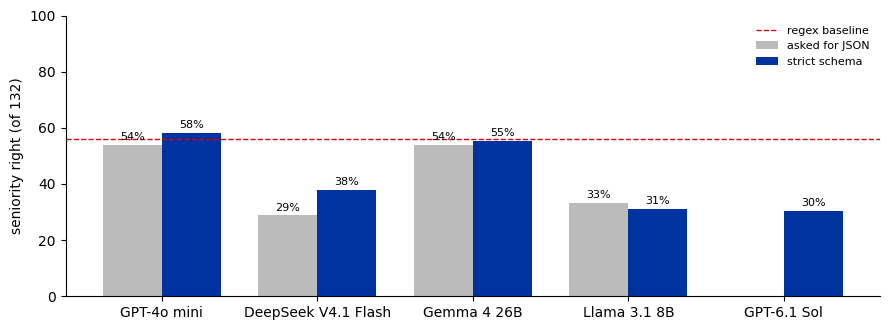

In [36]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, (mode, color, label) in enumerate((("prompt", "#BBBBBB", "asked for JSON"), ("schema", "#0033A0", "strict schema"))):
    rows_ = [(i, cmp[(cmp.model == SHORT[m]) & (cmp["mode"] == mode)]) for i, m in enumerate(MODELS)]
    rows_ = [(i, r["seniority right %"].iloc[0]) for i, r in rows_ if len(r)]
    bars = ax.bar([i + (k - 0.5) * 0.38 for i, _ in rows_], [v for _, v in rows_], width=0.38, color=color, label=label)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8, padding=2)
ax.axhline(100 * acc(base)[0], color="#D90012", lw=1, ls="--", label="regex baseline")
ax.set_xticks(range(len(MODELS)), [SHORT[m] for m in MODELS])
ax.set_ylabel(f"seniority right (of {len(scored)})")
ax.set_ylim(0, 100)
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

The schema mostly changes the format, not the reading: the numbers move by 2-9 points. The surprise
is the dashed line. **No model clearly beats the regex**: GPT-4o mini 58%, Gemma 55%, DeepSeek 38%, Llama 31%,
and the flagship, GPT-6.1 Sol, **30%**, against 56%.

The second accuracy column explains it. When they do name a level, GPT-4o mini is right 74% of the time, Gemma
72%, DeepSeek 81%, **GPT-6.1 Sol 82%**: as good as the regex (75%) or better. Llama, at 53%, is the only one that
really reads worse. The low first column is caution: DeepSeek names a level for only 62 of 132 postings, Sol for only
49, and both say `not_stated` for the rest, which the employer's key counts as wrong. Section 9 looks at who is
right in those cases.

## 9. Five models side by side (strict schema)

Years of experience and skills have no answer key, but we can ask whether the models **agree with each other**.

In [37]:
obj = {(r.model, r.id): r.obj for r in strict.itertuples() if isinstance(r.obj, dict)}


def skills_of(o):
    return {re.sub(r"\s+", " ", s.strip().lower()) for s in o.get("skills") or []}


same_years, n_pairs, jaccard = 0, 0, []
for i, m1 in enumerate(MODELS):
    for m2 in MODELS[i + 1:]:
        for job in jobs:
            a, b = obj.get((m1, job["id"])), obj.get((m2, job["id"]))
            if a and b:
                n_pairs += 1
                same_years += a.get("min_years_experience") == b.get("min_years_experience")
                if skills_of(a) | skills_of(b):
                    jaccard.append(len(skills_of(a) & skills_of(b)) / len(skills_of(a) | skills_of(b)))
print(f"same minimum years: {same_years / n_pairs:.0%} of {n_pairs} pairs of answers")
print(f"skills overlap (same spelling after lower-casing): {sum(jaccard) / len(jaccard):.0%} on average")

same minimum years: 96% of 1480 pairs of answers
skills overlap (same spelling after lower-casing): 36% on average


**Years are easy, skills are not.** Two models give the same number of years 96% of the time, but they share only
36% of their skills. Two postings show why:

In [38]:
EXAMPLES = [166766, 166762]          # the Full-Stack posting of section 1, and an operations manager
for jid in [i for i in EXAMPLES if i in by_id]:
    print(f"--- {by_id[jid]['title'].strip()}")
    for m in MODELS:
        print(f"   {SHORT[m]:<20} {(obj.get((m, jid)) or {}).get('skills', [])[:6]}")

--- Senior Full-Stack Developer (Angular / .NET Core)
   GPT-4o mini          ['Angular 12', 'ASP.NET Core 8', 'C#', 'SQL Server', 'REST APIs', 'AI-powered coding tools']
   DeepSeek V4.1 Flash  ['Angular 12', 'ASP.NET Core 8', 'C#', 'SQL Server', 'REST APIs', 'IIS']
   Gemma 4 26B          ['Angular 12', 'ASP.NET Core 8', 'C#', 'SQL Server', 'REST APIs', 'IIS/Windows']
   Llama 3.1 8B         ['Angular 12', '.NET Core 8', 'C#', 'SQL Server', 'REST APIs', 'backend services']
   GPT-6.1 Sol          ['Angular 12', 'ASP.NET Core 8', 'C#', 'SQL Server', 'REST APIs', 'IIS/Windows']
--- Operations Manager/ Farsi speaking
   GPT-4o mini          ['operations', 'performance management', 'business development', 'payments', 'fintech', 'financial services']
   DeepSeek V4.1 Flash  ['operations performance management', 'business development', 'payments', 'fintech', 'KYC', 'customer support']
   Gemma 4 26B          ['Business Administration', 'Finance', 'Economics', 'Data Analytics', 'CRM systems

On the Full-Stack posting the models agree on the core but not on the spelling ("ASP.NET Core 8" against ".NET
Core 8", "IIS" against "IIS/Windows"). On the operations manager they disagree about what a skill *is*: GPT-4o mini,
DeepSeek and GPT-6.1 Sol list what the job does, Gemma and Llama list the degrees it asks for. A skills field needs a fixed list
of allowed values (an `enum` again) before anyone can count on it.

Salary and remote work, against the employer's few filled-in fields:

In [39]:
PAY = re.compile(r"salary|\bAMD\b|\bUSD\b|\$|\bEUR\b|€|դրամ|աշխատավարձ|֏|зарплат|оклад", re.I)
pay_ids = {job["id"] for job in jobs if PAY.search(text_of(job))}
key_ids = {job["id"] for job in jobs if job["salary_from"] is not None or job["salary_to"] is not None}
remote_ids = {job["id"] for job in jobs if job["remote"]}
print(f"text mentions pay: {len(pay_ids)} | employer filled a salary: {len(key_ids)} | both: {len(pay_ids & key_ids)}"
      f" | remote ticked: {len(remote_ids)}")
out = []
for m in MODELS:
    o = {jid: v for (mm, jid), v in obj.items() if mm == m}
    found = {jid for jid, v in o.items() if v.get("salary")}
    out.append({"model": SHORT[m], "salary given": len(found), "text mentions pay": len(found & pay_ids),
                "text silent on pay": len(found - pay_ids), "says remote": sum(v.get("work_mode") == "remote" for v in o.values()),
                "says remote where ticked": sum(o.get(j, {}).get("work_mode") == "remote" for j in remote_ids)})
pd.DataFrame(out)

text mentions pay: 18 | employer filled a salary: 15 | both: 9 | remote ticked: 6


,model,salary given,text mentions pay,text silent on pay,says remote,says remote where ticked
0,GPT-4o mini,13,12,1,2,0
1,DeepSeek V4.1 Flash,6,5,1,2,0
2,Gemma 4 26B,5,4,1,2,0
3,Llama 3.1 8B,6,5,1,2,0
4,GPT-6.1 Sol,10,9,1,2,0


The employer filled in a salary 15 times, but the text mentions pay in only 9 of those: **a field on the form is
not a fact in the text.** Likewise, none of the five models says "remote" for the 6 postings where the box is
ticked: the text does not say so. Each model also gave one salary where our pay regex finds nothing in the text,
worth a look before anyone trusts that field.

Where do the seniority errors go? Rows: the employer's level. Columns: what the model answered.

In [40]:
for m in (STRONG, "openai/gpt-4o-mini"):
    s_ = strict[(strict.model == m) & strict.key.notna()]
    print(f"--- {SHORT[m]}")
    print(pd.crosstab(s_.key, s_.seniority.fillna("invalid")).reindex(index=["junior", "mid", "senior", "lead"],
                                                                     columns=SENIORITY, fill_value=0), "\n")

--- GPT-6.1 Sol
seniority  junior  mid  senior  lead  not_stated
key                                             
junior          7    0       0     0          19
mid             0    7       2     1          47
senior          0    0      22     6          16
lead            0    0       0     4           1 

--- GPT-4o mini
seniority  junior  mid  senior  lead  not_stated
key                                             
junior         17    3       0     0           6
mid             5   35       2     0          15
senior          0   10      21     6           7
lead            0    1       0     4           0 



The diagonal is "right". GPT-6.1 Sol rarely names a wrong level: 9 times in 49, every one a step *up* (6 seniors
it calls lead, 3 mids it calls senior or lead). Its weakness is the last column, **83 `not_stated`**, among them 47
of the 57 mid-level postings: a job ad rarely says "mid". GPT-4o mini commits far more often (28 `not_stated`) and
errs on both sides, 10 seniors called mid and 5 mids called junior. On this key, a bold guess scores better than
an honest "the text does not say".

Now the postings where the most models disagree with the employer's level:

In [41]:
wrong = Counter(r.id for r in strict.itertuples() if r.key and r.seniority and r.seniority != r.key)
for jid, n in sorted(wrong.items(), key=lambda kv: (-kv[1], kv[0]))[:3]:
    job = by_id[jid]
    answers = {SHORT[m]: (obj.get((m, jid)) or {}).get("seniority") for m in MODELS}
    print(f"--- {job['title'].strip()} | employer: {job['level']} | {answers}")
    print("   ", text_of(job)[:300].replace("\n", " "), "...\n")

--- .Net (C#) Developer | employer: Senior | {'GPT-4o mini': 'mid', 'DeepSeek V4.1 Flash': 'not_stated', 'Gemma 4 26B': 'mid', 'Llama 3.1 8B': 'junior', 'GPT-6.1 Sol': 'not_stated'}
    .Net (C#) Developer  Converse Bank CJSC is looking for an experienced .Net Developer to join our  rapidly growing team.  Participate in all the steps of the software project, from design to integration; Develop projects in accordance with given specifications; Collaborate with other developers on th ...

--- Software Engineer | employer: Senior | {'GPT-4o mini': 'mid', 'DeepSeek V4.1 Flash': 'not_stated', 'Gemma 4 26B': 'mid', 'Llama 3.1 8B': 'not_stated', 'GPT-6.1 Sol': 'not_stated'}
    Software Engineer  Do you want to solve business challenges through innovative technology? Do you enjoy working on cutting-edge, scalable services technology in a team environment? If this sounds interesting then go ahead and apply!  Collaborate with experienced cross-disciplinary team members, to c ...

--- Accountant

An "experienced .Net developer", a "Software Engineer" asked to work with "experienced" colleagues, an accountant
in Abovyan: the employer filed all three as Senior, but **the text never says so**. `not_stated` or `mid` is a fair
reading; the key calls it wrong.

> **Remember:** the answer key measures "can you guess the employer's form field", and part of that is not in the
> text at all. Real labels are noisy. Before blaming the model, read the cases where it "fails".

## 10. How sure was it? A review queue

The plan in production: trust confident answers, send unsure ones to a person. First, is confidence even linked
to being right?

In [42]:
conf = strict[strict.key.notna() & strict.seniority.notna()].copy()
conf["right"] = conf.seniority == conf.key
print("seniority probability readable:",
      {SHORT[m]: f"{v:.0%}" for m, v in strict.groupby("model")["p"].apply(lambda s: s.notna().mean()).reindex(MODELS).items()})
bands = pd.cut(conf.p, [0, 0.6, 0.9, 0.99, 1.0001], right=False, labels=["< 0.6", "0.6-0.9", "0.9-0.99", ">= 0.99"])
(conf.assign(band=bands).groupby(["model", "band"], observed=False)["right"].agg(["mean", "size"])
 .rename(columns={"mean": "share right", "size": "replies"}).reindex([m for m in MODELS if m != STRONG], level=0)
 .rename(index=SHORT, level=0).round(2))

seniority probability readable: {'GPT-4o mini': '100%', 'DeepSeek V4.1 Flash': '95%', 'Gemma 4 26B': '100%', 'Llama 3.1 8B': '100%', 'GPT-6.1 Sol': '0%'}


share right  replies
model               band                          
GPT-4o mini         < 0.6            0.42       12
                    0.6-0.9          0.44       25
                    0.9-0.99         0.40       30
                    >= 0.99          0.75       65
DeepSeek V4.1 Flash < 0.6            0.00        2
                    0.6-0.9          0.43       21
                    0.9-0.99         0.12       32
                    >= 0.99          0.54       69
Gemma 4 26B         < 0.6            0.00        2
                    0.6-0.9          0.30       10
                    0.9-0.99         0.42       12
                    >= 0.99          0.60      108
Llama 3.1 8B        < 0.6            0.21       47
                    0.6-0.9          0.24       68
                    0.9-0.99         0.80       10
                    >= 0.99          1.00        7

A little. GPT-4o mini is right 75% of the time when it is at least 99% sure, and about 40% of the time below
that. Gemma is at least 99% sure in 108 of its 132 answers, and right in only 60% of those: **confident is not the
same as correct.** Llama is the opposite, rarely sure of anything.

The review-queue curve: send the least sure postings to a person first, and watch the errors that are left.

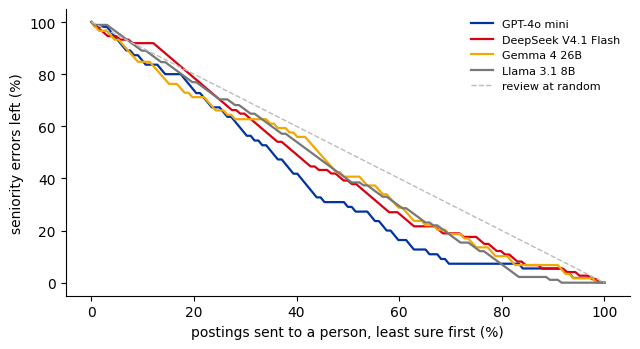

share to review to remove half the errors: {'GPT-4o mini': '36%', 'DeepSeek V4.1 Flash': '40%', 'Gemma 4 26B': '45%', 'Llama 3.1 8B': '43%'}


In [43]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
halve = {}
for m in MODELS:
    c = conf[(conf.model == m) & conf.p.notna()].sort_values("p")
    if c.empty:
        continue                                             # GPT-6.1 Sol offers no logprobs
    errors = (~c.right).to_numpy()
    xs = [k / len(c) for k in range(len(c) + 1)]
    left = [errors[k:].sum() / errors.sum() for k in range(len(c) + 1)]
    ax.plot([100 * v for v in xs], [100 * v for v in left], color=COLOR[m], lw=1.6, label=SHORT[m])
    halve[m] = next(x for x, l in zip(xs, left) if l <= 0.5)
ax.plot([0, 100], [100, 0], color="#BBBBBB", lw=1, ls="--", label="review at random")
ax.set_xlabel("postings sent to a person, least sure first (%)")
ax.set_ylabel("seniority errors left (%)")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
print("share to review to remove half the errors:", {SHORT[m]: f"{v:.0%}" for m, v in halve.items()})

The five postings GPT-4o mini was least sure about, the first ones a reviewer would see:

In [44]:
least = conf[conf.model == "openai/gpt-4o-mini"].sort_values("p").head(5)
for r in least.itertuples():
    print(f"p = {r.p:.2f}  answer: {r.seniority:<10} employer: {r.key:<6}  {by_id[r.id]['title'].strip()[:60]}")

p = 0.44  answer: mid        employer: junior  Համակցման տեխնիկ ք․ Եղեգնաձոր
p = 0.49  answer: mid        employer: mid     ML Validator_Model Risk and Analytics Division
p = 0.50  answer: junior     employer: junior  Internship in the Site Implementation Unit
p = 0.51  answer: junior     employer: junior  Համակցման տեխնիկ ք. Գյումրի
p = 0.55  answer: not_stated employer: mid     Graphic Designer


Every curve beats random review, but not by much: to remove half the errors, a person has to check **36-45% of
all postings**. The outline predicted about 20%.

> **Remember:** a logprob measures how sure the model is **about the text**. Most "errors" here are postings
> where the text simply does not say the level, and the model is (rightly) sure that it does not. No confidence
> score can recover information that is not in the input.

## 11. Armenian vs English

31 Armenian postings against 116 English ones, by the letters (section 1). Small numbers: read the counts too.

In [45]:
lang_rows = []
for m in MODELS:
    for lg in ("en", "am"):
        sub = strict[(strict.model == m) & (strict.lang == lg)]
        sc = sub[sub.key.notna()]
        lang_rows.append({"model": SHORT[m], "language": lg, "postings": len(sub),
                          "seniority right": f"{(sc.seniority == sc.key).mean():.0%} of {len(sc)}",
                          "said not_stated": int((sc.seniority == "not_stated").sum()),
                          "prompt tokens (median)": int(sub.prompt_tokens.median()),
                          "$ per 1,000 postings": round(1000 * sub.cost.sum() / len(sub), 3)})
pd.DataFrame(lang_rows)

,model,language,postings,seniority right,said not_stated,prompt tokens (median),"$ per 1,000 postings"
0,GPT-4o mini,en,116,62% of 103,18,681,0.146
1,GPT-4o mini,am,31,46% of 28,9,716,0.178
2,DeepSeek V4.1 Flash,en,116,48% of 103,43,790,0.394
3,DeepSeek V4.1 Flash,am,31,4% of 28,26,1154,0.617
4,Gemma 4 26B,en,116,63% of 103,19,573,0.087
5,Gemma 4 26B,am,31,29% of 28,10,905,0.122
6,Llama 3.1 8B,en,116,38% of 103,38,569,0.157
7,Llama 3.1 8B,am,31,4% of 28,17,2672,0.691
8,GPT-6.1 Sol,en,116,39% of 103,55,675,2.406
9,GPT-6.1 Sol,am,31,0% of 28,27,710,2.562


Every model reads Armenian worse: GPT-4o mini drops from 62% to 46%, Gemma from 63% to 29%, DeepSeek and Llama to
4%. The flagship gets **none of the 28** right: it answers `not_stated` on 27 of them. And Armenian costs more:
Llama's tokenizer needs **4.7x** the tokens for an Armenian posting (2,672 against 569), so its price per 1,000
postings more than quadruples. GPT-4o mini's tokenizer hardly notices (716 against 681), nor does GPT-6.1 Sol's (710
against 675).

> **Remember:** LLM-1's "Armenian tax" is real money and real accuracy. Test on the language you will actually
> serve, not on the English benchmark.

## 12. Temperature 0, twice

Pass 3 is pass 2 again: same model, same endpoint, same text, temperature 0. Do the answers repeat?

In [46]:
twice = df[df["mode"] == "schema"].set_index(["model", "id", "rep"])["obj"].unstack("rep")
same_rows = []
for m in [m for m in MODELS if ("schema", 1) in PASSES[m]]:
    t = twice.loc[m]
    pairs = [(a, b) for a, b in zip(t[0], t[1]) if isinstance(a, dict) and isinstance(b, dict)]
    changed = [(a, b) for a, b in pairs if a != b]
    fields = Counter(f for a, b in changed for f in a if a.get(f) != b.get(f))
    same_rows.append({"model": SHORT[m], "compared": len(pairs), "any field changed": len(changed),
                      "seniority changed": fields.get("seniority", 0), "fields that changed": dict(fields)})
pd.DataFrame(same_rows)

,model,compared,any field changed,seniority changed,fields that changed
0,GPT-4o mini,148,49,5,"{'seniority': 5, 'work_mode': 4, 'skills': 45, 'salary': 1}"
1,DeepSeek V4.1 Flash,148,63,4,"{'skills': 62, 'seniority': 4}"
2,Gemma 4 26B,148,65,5,"{'skills': 60, 'seniority': 5, 'salary': 2, 'work_mode': 1}"
3,Llama 3.1 8B,148,8,1,"{'skills': 8, 'seniority': 1}"


For three of the four models, **a third or more of the answers changed** (49, 63 and 65 of 148), almost all in the
skills list; seniority changed 4-5 times. Llama was the steadiest (8). LLM-2 explained why: batching on the
provider's side changes the arithmetic in the last digits, and near-ties flip. (GPT-6.1 Sol ran once, so it
is not in this table.)

One answer that changed, GPT-4o mini, first run against second run:

In [47]:
t = twice.loc["openai/gpt-4o-mini"]
jid, a, b = next((i, a, b) for i, a, b in zip(t.index, t[0], t[1]) if isinstance(a, dict) and isinstance(b, dict) and a != b)
print(by_id[jid]["title"].strip())
for f in a:
    if a[f] != b[f]:
        print(f"  {f}:\n    run 1: {a[f]}\n    run 2: {b[f]}")

Համակցման տեխնիկ ք. Երևան
  seniority:
    run 1: mid
    run 2: junior
  work_mode:
    run 1: not_stated
    run 2: on_site


> **Remember:** temperature 0 makes answers *likely* to repeat, not *certain*. If two runs must agree, store the
> first answer; do not ask again.

## 13. Would you ship it?

Everything in one table (strict schema, except the "asked" column).

In [48]:
summary = []
for m in MODELS:
    s, p = strict[strict.model == m], first[(first.model == m) & (first["mode"] == "prompt")]
    row = next((r for r in same_rows if r["model"] == SHORT[m]), None)
    summary.append({"model": SHORT[m], "seniority right %": round(100 * acc(pred_of(s))[0], 1),
                    "right when it named a level %": round(100 * acc(pred_of(s))[1], 1),
                    "unusable JSON, asked": int((~p["status"].isin(["clean", "needed cleanup"])).sum()) if len(p) else "-",
                    "unusable JSON, strict": int((~s["status"].isin(["clean", "needed cleanup"])).sum()),
                    "$ per 1,000 postings": round(1000 * s.cost.sum() / len(s), 3), "median s": s.secs.median(),
                    "review to halve errors": f"{halve[m]:.0%}" if m in halve else "-",
                    "changed on rerun": row["any field changed"] if row else "-"})
sol_cost = sum(c.get("cost") or 0 for k, c in calls.items() if k.startswith(STRONG))
print(f"regex baseline: {100 * acc(base)[0]:.1f}% ({100 * acc(base)[1]:.1f}% when it named a level) | saved run: "
      f"{len(calls)} calls, ${sum(c.get('cost') or 0 for c in calls.values()):.4f} (GPT-6.1 Sol ${sol_cost:.4f}) | "
      f"live calls today: ${sum(c.get('cost') or 0 for c in live.values()):.5f}")
pd.DataFrame(summary)

regex baseline: 56.1% (74.7% when it named a level) | saved run: 1924 calls, $0.7500 (GPT-6.1 Sol $0.3613) | live calls today: $0.00345


,model,seniority right %,right when it named a level %,"unusable JSON, asked","unusable JSON, strict","$ per 1,000 postings",median s,review to halve errors,changed on rerun
0,GPT-4o mini,58.3,74.0,1,0,0.153,1.565,36%,49
1,DeepSeek V4.1 Flash,37.9,80.6,10,0,0.441,0.785,40%,63
2,Gemma 4 26B,55.3,71.6,4,0,0.094,0.880,45%,65
3,Llama 3.1 8B,31.1,53.2,56,0,0.269,0.900,43%,8
4,GPT-6.1 Sol,30.3,81.6,-,0,2.441,2.700,-,-


**For the format: yes.** A strict schema gives valid JSON every time, from every model, at no extra cost.

**For seniority: not as it stands.** None of the five beats three regexes on the employer's key, mostly because the
key asks for something the text does not say. **A bigger model does not help**: GPT-6.1 Sol costs 16x GPT-4o mini
per posting and scores 30%, because it will not guess what the text leaves out. The honest next step is a better
question (add `not_stated` to the key, or grade only postings whose text names a level) and a fixed skills list.

**For the bill:** Gemma 4 26B is the cheapest at $0.09 per 1,000 postings and about as accurate as GPT-4o mini;
DeepSeek is the dearest cheap model at $0.44, because the endpoint test sent it to a premium endpoint, partly
through a bug of ours (section 4). GPT-6.1 Sol costs
$2.44 per 1,000 postings and takes 2.7 s a call. This whole notebook, 1,924 calls, cost **$0.75**: $0.39 for the
four cheap models, $0.36 for Sol's 148.

| Predicted before the run (outline) | Measured |
|---|---|
| Strict schema: 0 invalid for every model | **Right**: 0 of 740 |
| Prompt only: 5-15% invalid for Llama, about 0 for GPT-4o mini | Llama **38%** unusable; GPT-4o mini 1 of 148; Gemma fenced all 148 in code blocks |
| Baseline 50-60%, the LLMs 70-85% | Baseline 56%; the LLMs **30-58%** (53-82% where they name a level) |
| The employer's key caps everyone below 100% | Right, and by far more than expected |
| Reviewing the least sure 20% removes half the errors | It takes **36-45%** |
| Armenian: lower accuracy, 2-4x the tokens on GPT-4o mini and Llama | Lower accuracy for all; Llama **4.7x**, GPT-4o mini only 1.05x |
| Temperature 0: a few percent of answers change | **33-44%** for three models (mostly skills) |
| Added after the first run: a flagship model fixes it | **No**: GPT-6.1 Sol is the most precise (82% when it names a level) and the lowest overall (30%) |